# Bike Sharing Demand Prediction

**ML Zoomcamp — Midterm Project**

* **Task:** regression — predict how many bikes are rented (`cnt`) in every hour of the next day.
* **Data:** UCI Bike Sharing Dataset, `data/hour.csv` — 17,379 hourly records from 2011-01-01 to 2012-12-31.
* **Inputs:** calendar information only — season, year, month, hour, holiday, weekday, working day.
* **Metric:** RMSLE, which is the RMSE computed on `log1p(cnt)`. Count-scale RMSE and MAE are reported as
  secondary numbers (predictions are `expm1`-ed back and clipped at 0).
* **Why only calendar features:** the weather columns in this dataset are *observed* weather. At the end of
  the day we do not know the weather of the next day, so a real day-ahead forecast cannot use `temp`,
  `hum`, `windspeed` or `weathersit`. Those columns are looked at in the EDA for context only.

Notebook outline: setup → EDA → feature choice → chronological split → baselines → models → tuning →
comparison → one final test evaluation → saving the model.

## 1. Setup

The notebook uses only the libraries from the project `Pipfile`
(pandas, NumPy, scikit-learn, XGBoost, matplotlib, seaborn).

This cell fixes the seed, the paths and prints the library versions, so the run can be reproduced later.

In [1]:
import hashlib
import os
import pickle
import platform
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

%matplotlib inline
sns.set_theme(style="whitegrid")

SEED = 42                   # random state used for the final model and for NumPy
SEEDS = [0, 1, 2, 3, 4]     # 5 seeds for repeated stochastic models -> we report mean +- std
DATA_PATH = "data/hour.csv"
MODEL_PATH = "models/bike_demand_model.bin"

np.random.seed(SEED)
pd.set_option("display.max_columns", 60)

print("python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgb.__version__)

def _git_sha():
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        return None

print("git sha     :", _git_sha())

python      : 3.12.15
pandas      : 3.0.6
numpy       : 2.5.4
scikit-learn: 1.9.1
xgboost     : 3.4.1
git sha     : 4650373b91c0c0eb15534db44d04b6d84e83df88


## 2. Load the data

`dteday` is parsed as a date because it is needed for the time-based split.
The SHA-256 of the file is printed so that the run can be tied to an exact dataset version.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["dteday"])

# dataset fingerprint (see docs/conventions/ml.md: every run records the dataset version)
with open(DATA_PATH, "rb") as f:
    dataset_hash = hashlib.sha256(f.read()).hexdigest()

print("shape         :", df.shape)
print("dataset sha256:", dataset_hash)
print("date range    :", df["dteday"].min().date(), "->", df["dteday"].max().date())
df.head(3)

shape         : (17379, 17)
dataset sha256: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f
date range    : 2011-01-01 -> 2012-12-31


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


## 3. Exploratory data analysis

This section has two parts.

* **Data-quality checks** use the whole file (missing values, duplicates, day completeness).
* **Target-driven plots** that inform feature/model decisions are drawn from the **training split only**,
  so the validation and test periods stay untouched until the final evaluation.

In [3]:
print("missing values per column:")
print(df.isna().sum().to_string())
print()
print("duplicated rows             :", int(df.duplicated().sum()))
print("duplicated (day, hour) pairs:", int(df.duplicated(["dteday", "hr"]).sum()))
print("unique days                 :", int(df["dteday"].nunique()))

hours_per_day = df.groupby("dteday")["hr"].nunique()
print("hours per day (days with that many):", hours_per_day.value_counts().sort_index().to_dict())
print("days with fewer than 24 rows      :", int((hours_per_day < 24).sum()))

missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0

duplicated rows             : 0
duplicated (day, hour) pairs: 0
unique days                 : 731
hours per day (days with that many): {1: 1, 8: 1, 11: 1, 12: 1, 16: 1, 17: 1, 18: 2, 22: 6, 23: 62, 24: 655}
days with fewer than 24 rows      : 76


No missing values and no duplicated `(day, hour)` pairs. The hourly grid is not perfectly complete
though: 655 of the 731 days have all 24 rows and 76 days are shorter. Most of them miss one hour, a few
are heavily truncated (2011-01-18 has 12 rows, 2011-01-27 has 8, 2012-10-29 has a single row — the day
Hurricane Sandy hit the area). The rows are left as they are: the target is only known for hours that
were recorded, and dropping whole days would throw away good data.

Column types: `dteday` is a date, `cnt` / `casual` / `registered` are integers, weather variables are
floats between 0 and 1, and calendar variables are integer codes (`season` 1–4, `weathersit` 1–4,
`weekday` 0–6 where 0 is Sunday).

training cnt distribution:
count    13003.00
mean       167.71
std        160.79
min          1.00
25%         35.00
50%        124.00
75%        246.00
max        957.00


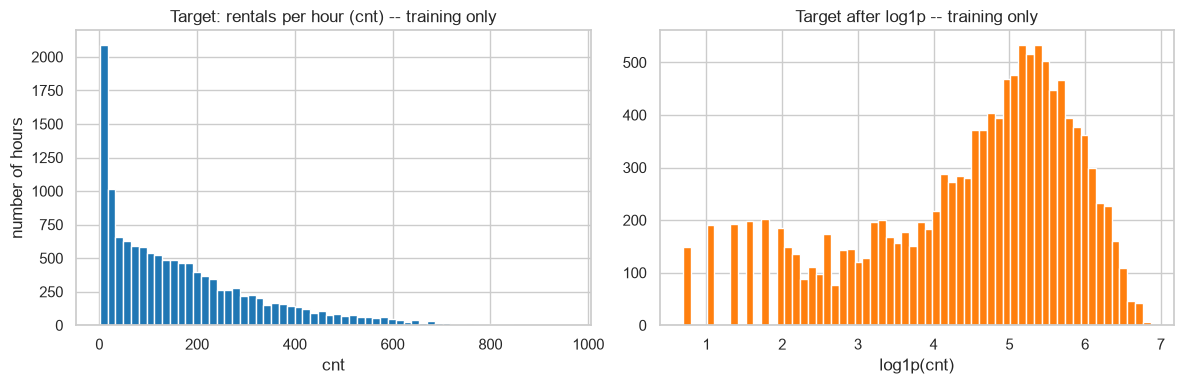

In [4]:
# Training-only target distribution. log1p compresses the tail, and RMSE on log1p(cnt)
# is exactly RMSLE. We compute log_cnt for the whole frame because it is needed later;
# the plots below look at training rows only.
df["log_cnt"] = np.log1p(df["cnt"])

TRAIN_END = pd.Timestamp("2012-06-30")
VALID_END = pd.Timestamp("2012-09-30")
train_eda = df[df["dteday"] <= TRAIN_END].copy()

print("training cnt distribution:")
print(train_eda["cnt"].describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_eda["cnt"], bins=60, color="tab:blue")
axes[0].set_title("Target: rentals per hour (cnt) -- training only")
axes[0].set_xlabel("cnt")
axes[0].set_ylabel("number of hours")

axes[1].hist(train_eda["log_cnt"], bins=60, color="tab:orange")
axes[1].set_title("Target after log1p -- training only")
axes[1].set_xlabel("log1p(cnt)")
plt.tight_layout()

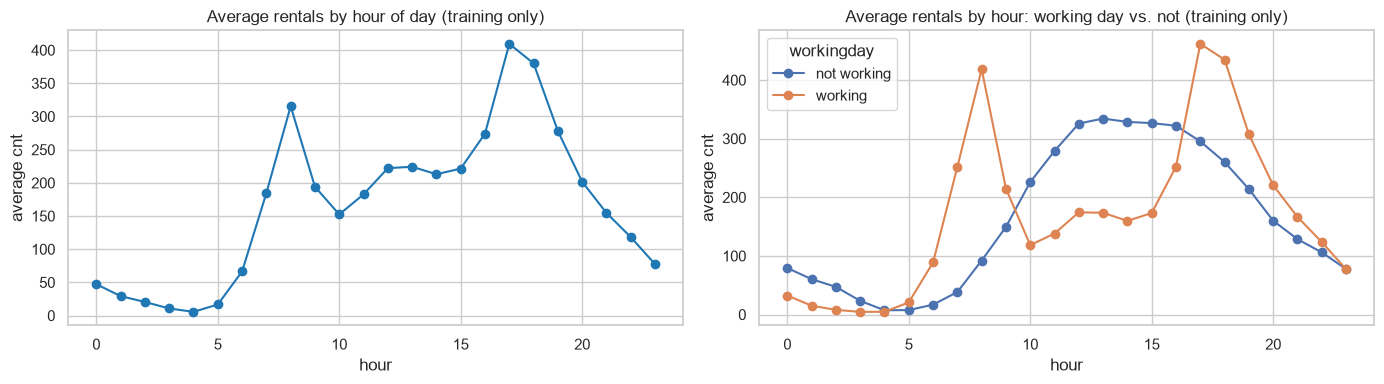

In [5]:
# Hour of the day is the strongest signal: two commute peaks on working days.
# Plotted on the training split so the feature decision is not influenced by held-out targets.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

train_eda.groupby("hr")["cnt"].mean().plot(ax=axes[0], marker="o", color="tab:blue")
axes[0].set_title("Average rentals by hour of day (training only)")
axes[0].set_xlabel("hour")
axes[0].set_ylabel("average cnt")

train_eda.groupby(["hr", "workingday"])["cnt"].mean().unstack().plot(ax=axes[1], marker="o")
axes[1].set_title("Average rentals by hour: working day vs. not (training only)")
axes[1].set_xlabel("hour")
axes[1].set_ylabel("average cnt")
axes[1].legend(title="workingday", labels=["not working", "working"])
plt.tight_layout()

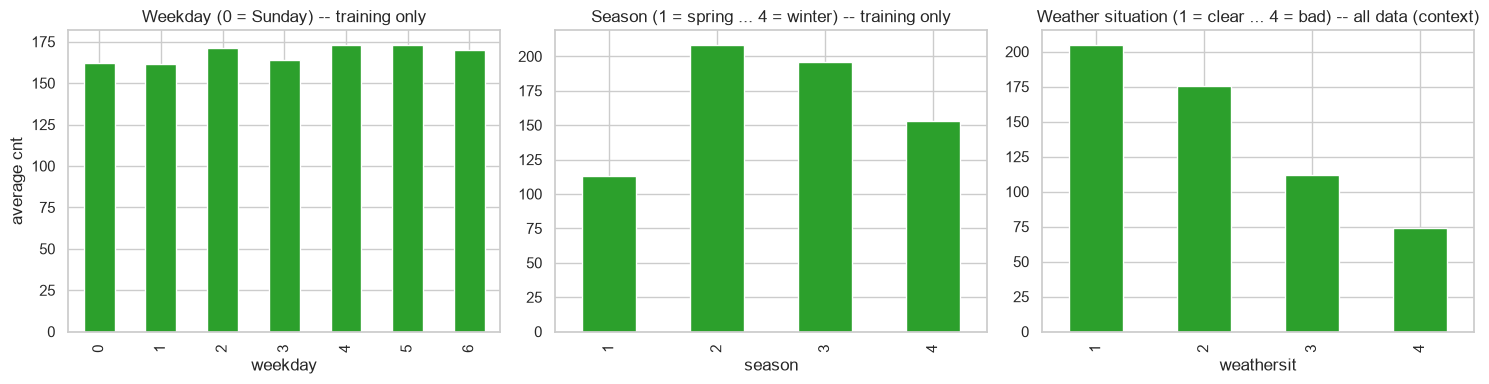

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Weekday and season use training targets only; weather is observed and stays out of the model,
# so its plot is shown for context on the whole dataset.
train_eda.groupby("weekday")["cnt"].mean().plot(kind="bar", ax=axes[0], color="tab:green")
axes[0].set_title("Weekday (0 = Sunday) -- training only")
axes[0].set_ylabel("average cnt")

train_eda.groupby("season")["cnt"].mean().plot(kind="bar", ax=axes[1], color="tab:green")
axes[1].set_title("Season (1 = spring ... 4 = winter) -- training only")

df.groupby("weathersit")["cnt"].mean().plot(kind="bar", ax=axes[2], color="tab:green")
axes[2].set_title("Weather situation (1 = clear ... 4 = bad) -- all data (context)")
plt.tight_layout()

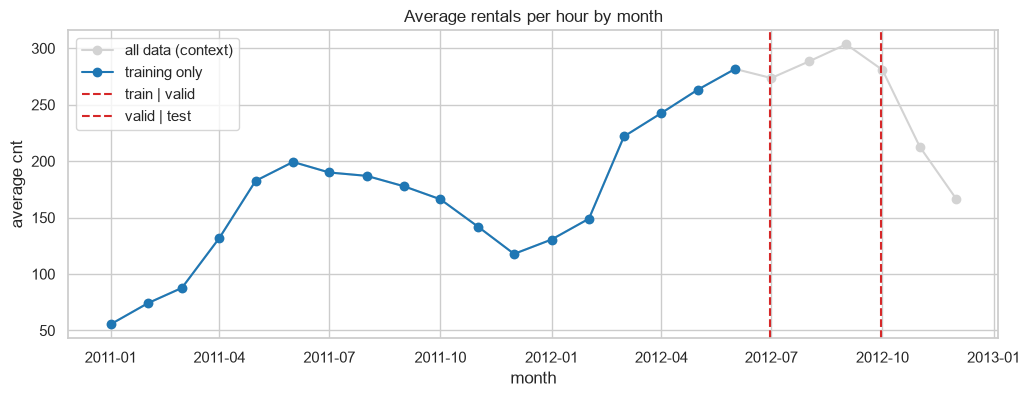

In [7]:
# Monthly trend: demand grows over the two years and is strongly seasonal.
# Training-only means, with the full-data trend shown lightly for context.
monthly_train = train_eda.groupby(train_eda["dteday"].dt.to_period("M"))["cnt"].mean()
monthly_train.index = monthly_train.index.to_timestamp()
monthly_all = df.groupby(df["dteday"].dt.to_period("M"))["cnt"].mean()
monthly_all.index = monthly_all.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly_all, marker="o", color="lightgray", label="all data (context)")
ax.plot(monthly_train, marker="o", color="tab:blue", label="training only")
ax.set_title("Average rentals per hour by month")
ax.set_ylabel("average cnt")
ax.set_xlabel("month")
ax.axvline(pd.Timestamp("2012-06-30"), color="tab:red", linestyle="--", label="train | valid")
ax.axvline(pd.Timestamp("2012-09-30"), color="tab:red", linestyle="--", label="valid | test")
ax.legend()

In [8]:
# Correlations with the target. casual + registered are the two parts of cnt (leakage),
# the weather columns are only observed after the fact. Computed on the training split only.
numeric_cols = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
train_eda[numeric_cols].corr()["cnt"].sort_values(ascending=False).round(3).to_frame("corr with cnt -- training only")

,corr with cnt -- training only
cnt,1.000
registered,0.968
casual,0.709
temp,0.417
atemp,0.413
windspeed,0.106
hum,-0.324


### What the EDA shows

* Demand has a clear **daily shape** (two peaks at 8:00 and 17:00) and a different shape on working
  days vs. weekends, so `hr × workingday` is the key interaction to capture.
* Demand is **higher in warm months** in the training data, so the model needs season and month.
  The training data also show growth from 2011 to 2012, which is what the `yr` feature is for.
* `weathersit` correlates with demand (bad weather → fewer rentals), but only *observed* weather is in
  the file. Predicting tomorrow with it would be leakage from the future, so it stays out of the model.
* `casual` and `registered` add up to `cnt` exactly. Using them as features would be target leakage.
* The target spans about 0 to ~1000 rentals per hour, so `log1p` is used and the error is measured as
  RMSLE. A plain RMSE on counts would be dominated by the few very busy hours.

## 4. Features and target

Kept: `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday` — all known a day in advance.

Dropped on purpose:

| column | why |
|---|---|
| `instant` | row id, carries no information |
| `dteday` | used only to build the chronological split |
| `casual`, `registered` | they sum to `cnt` → target leakage |
| `temp`, `atemp`, `hum`, `windspeed`, `weathersit` | observed weather, unknown for tomorrow |

The features are converted to strings so that one-hot encoding treats them as categories
(`hr=3` is not "three times hour 1").

In [9]:
# leakage check: cnt must be exactly casual + registered, so neither may be a feature
print("rows where casual + registered != cnt:", int((df["casual"] + df["registered"] != df["cnt"]).sum()))

CATEGORICAL_FEATURES = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday"]

for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype(str)

print("levels per feature:")
print(df[CATEGORICAL_FEATURES].nunique().to_string())

rows where casual + registered != cnt: 0
levels per feature:
season         4
yr             2
mnth          12
hr            24
holiday        2
weekday        7
workingday     2


## 5. Train / validation / test split (chronological)

The project predicts **tomorrow** from **today**, so the evaluation must copy that: train on the past,
validate on the next months, test on the months after that. A random split would mix future hours into
the training data and overstate the accuracy.

Following `docs/conventions/ml.md`:

| split | dates | rows |
|---|---|---|
| train | 2011-01-01 → 2012-06-30 | 13,003 |
| validation | 2012-07-01 → 2012-09-30 | 2,208 |
| test | 2012-10-01 → 2012-12-31 | 2,168 |

The test period is used **once**, at the very end, for the final number. Every choice (features,
hyperparameters, number of boosting rounds) is made on the validation period only.

In [10]:
# These cutoffs are also used in the EDA cell, so they are defined once here.
TRAIN_END = pd.Timestamp("2012-06-30")
VALID_END = pd.Timestamp("2012-09-30")

train = df[df["dteday"] <= TRAIN_END].copy()
valid = df[(df["dteday"] > TRAIN_END) & (df["dteday"] <= VALID_END)].copy()
test = df[df["dteday"] > VALID_END].copy()

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(
        f"{name:5s}: {len(part):5d} rows | "
        f"{part['dteday'].min().date()} -> {part['dteday'].max().date()} | "
        f"mean cnt {part['cnt'].mean():6.1f}"
    )

train: 13003 rows | 2011-01-01 -> 2012-06-30 | mean cnt  167.7
valid:  2208 rows | 2012-07-01 -> 2012-09-30 | mean cnt  288.4
test :  2168 rows | 2012-10-01 -> 2012-12-31 | mean cnt  219.2


One thing to keep in mind: the average `cnt` is not constant across the periods. Demand in
October–December is lower than in July–September, so the test period is a bit harder than the
validation period. The gap between validation and test scores therefore measures **drift**, not only
model quality.

### Building the feature matrices

One-hot encoding with pandas keeps the column set fixed: the encoder is built on the training rows, and
the other periods are re-indexed to the same columns. Category levels that never appear in training
would become all-zero columns (none appear here, but the `reindex` makes the behaviour explicit).

A note for anyone comparing with the course notebooks: `DictVectorizer.transform()` returns a matrix
whose width depends on the keys present in the batch — with a chronological split (months 7–9 only) it
silently returns fewer columns than it was fitted with, which breaks the alignment between the model
and the new data. Building the matrix with `get_dummies` + `reindex` avoids that bug.

In [11]:
def make_features(frame, columns=None):
    """One-hot encode the calendar features with a fixed column set."""
    encoded = pd.get_dummies(frame[CATEGORICAL_FEATURES], dtype=float)
    if columns is not None:
        encoded = encoded.reindex(columns=columns, fill_value=0.0)
    return encoded


X_train = make_features(train)
FEATURES = list(X_train.columns)        # the encoder is defined by the training split only
X_valid = make_features(valid, FEATURES)
X_test = make_features(test, FEATURES)

y_train = train["log_cnt"].to_numpy()
y_valid = valid["log_cnt"].to_numpy()
y_test = test["log_cnt"].to_numpy()

print("number of features:", len(FEATURES))
print("train matrix:", X_train.shape, "| valid matrix:", X_valid.shape, "| test matrix:", X_test.shape)

number of features: 53
train matrix: (13003, 53) | valid matrix: (2208, 53) | test matrix: (2168, 53)


## 6. Baselines

Before training anything, two trivial predictors set the bar:

1. **global mean** — predict the average `log1p(cnt)` of the training period for every hour;
2. **weekday × hour profile** — average `log1p(cnt)` of the same weekday and hour in the training period.

If a model cannot beat the second baseline, it has learnt nothing beyond the calendar.

In [12]:
def rmse(y_true, y_pred):
    """RMSE; on the log1p target this is exactly RMSLE."""
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


results = []


def add_result(name, scores):
    """Store mean +- std of the RMSLE of a model over its seeds."""
    results.append(
        {
            "model": name,
            "rmsle_mean": float(np.mean(scores)),
            "rmsle_std": float(np.std(scores)),
        }
    )


train_mean = float(y_train.mean())

pred_global_mean = np.full(len(y_valid), train_mean)
add_result("baseline: global mean", [rmse(y_valid, pred_global_mean)])

profile = train.groupby(["weekday", "hr"])["log_cnt"].mean()
valid_keys = list(zip(valid["weekday"], valid["hr"]))
pred_profile = np.array([profile.get(key, train_mean) for key in valid_keys])
add_result("baseline: weekday x hour mean", [rmse(y_valid, pred_profile)])

pd.DataFrame(results).round(4)

,model,rmsle_mean,rmsle_std
0,baseline: global mean,1.4867,0.0
1,baseline: weekday x hour mean,0.7332,0.0


## 7. Model 1 — linear regression

The simplest real model: one weight per one-hot column. It can only add up the effects of season, hour,
weekday and so on, so it cannot represent "the 8:00 peak only exists on working days" unless that
combination is a column of its own.

In [13]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
pred_lin = lin_model.predict(X_valid)

add_result("linear regression", [rmse(y_valid, pred_lin)])
print("linear regression RMSLE:", round(rmse(y_valid, pred_lin), 4))

# a quick look at what the model has learnt
coefficients = pd.Series(lin_model.coef_, index=FEATURES).sort_values()
print()
print("lowest coefficients:")
print(coefficients.head(3).round(3).to_string())
print("highest coefficients:")
print(coefficients.tail(3).round(3).to_string())

linear regression RMSLE: 0.5898

lowest coefficients:
hr_4   -2.761
hr_3   -2.427
hr_2   -1.912
highest coefficients:
hr_16    1.022
hr_18    1.322
hr_17    1.408


## 8. Tree-based models

A decision tree splits the data on feature values and therefore learns interactions (hour × working
day) without being told about them. Two versions:

* a single **decision tree**, depth-limited so it does not memorise single hours;
* a **random forest** — many trees on bootstrap samples, which removes most of the variance of one tree.

Both are stochastic, so each one is trained with the 5 seeds from `SEEDS` and we report mean ± std.

In [14]:
tree_scores = []
for seed in SEEDS:
    tree = DecisionTreeRegressor(max_depth=8, random_state=seed)
    tree.fit(X_train, y_train)
    tree_scores.append(rmse(y_valid, tree.predict(X_valid)))

add_result("decision tree (max_depth=8)", tree_scores)
print("decision tree: %.4f +- %.4f" % (np.mean(tree_scores), np.std(tree_scores)))

decision tree: 0.7002 +- 0.0002


In [15]:
forest_scores = []
for seed in SEEDS:
    forest = RandomForestRegressor(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=2,
        random_state=seed,
        n_jobs=-1,
    )
    forest.fit(X_train, y_train)
    forest_scores.append(rmse(y_valid, forest.predict(X_valid)))

add_result("random forest (100 trees)", forest_scores)
print("random forest: %.4f +- %.4f" % (np.mean(forest_scores), np.std(forest_scores)))

random forest: 0.3941 +- 0.0013


## 9. XGBoost (gradient boosting)

Boosting builds trees one after another, each one correcting the errors of the previous ones. The
settings follow the course defaults:

* `objective="reg:squarederror"` on the `log1p` target → RMSE on the log scale → RMSLE;
* `eta` (learning rate) small enough that many trees are useful;
* **early stopping** on the validation split: training stops when the validation RMSE has not improved
  for 50 rounds. The best iteration is remembered and reused later.

The validation split is used for early stopping and for choosing hyperparameters. This is the standard
course workflow, and it makes the validation score slightly optimistic — one more reason to keep the
test period untouched.

In [16]:
# XGBoost gets the same one-hot matrix; DMatrix keeps the pandas column names as feature names.
dtrain = xgb.DMatrix(X_train, label=y_train)
dvalid = xgb.DMatrix(X_valid, label=y_valid)

BASE_PARAMS = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "eta": 0.1,
    "max_depth": 6,
    "min_child_weight": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "nthread": 4,
    "seed": SEED,
}
MAX_ROUNDS = 500
EARLY_STOPPING_ROUNDS = 50


def train_booster(params):
    """Train one boosted model with early stopping on the validation set."""
    history = {}
    booster = xgb.train(
        params,
        dtrain,
        num_boost_round=MAX_ROUNDS,
        evals=[(dvalid, "valid")],
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        evals_result=history,
        verbose_eval=False,
    )
    return booster, history


def predict_booster(booster, dmatrix):
    """Predict with the trees that were kept by early stopping."""
    return booster.predict(dmatrix, iteration_range=(0, booster.best_iteration + 1))


booster, history = train_booster(BASE_PARAMS)
print("best iteration      :", booster.best_iteration)
print("validation RMSLE    :", round(rmse(y_valid, predict_booster(booster, dvalid)), 4))

best iteration      : 213
validation RMSLE    : 0.3185


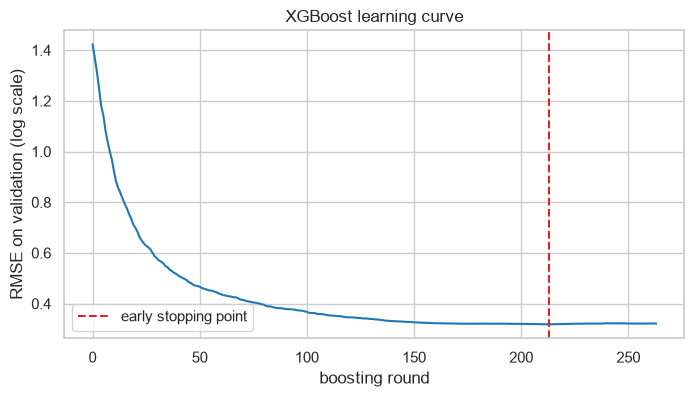

In [17]:
# Learning curve: the validation error drops quickly and then flattens out.
plt.figure(figsize=(8, 4))
plt.plot(history["valid"]["rmse"], color="tab:blue")
plt.axvline(booster.best_iteration, color="tab:red", linestyle="--", label="early stopping point")
plt.xlabel("boosting round")
plt.ylabel("RMSE on validation (log scale)")
plt.title("XGBoost learning curve")
plt.legend()

## 10. Hyperparameter tuning

A small grid over the two settings that matter most — learning rate `eta` and tree depth. Every
combination is trained with all 5 seeds, so the comparison is not based on one lucky run.

The search is deliberately small (6 combinations × 5 seeds = 30 fits, about half a minute on a laptop).

In [18]:
ETAS = [0.05, 0.1]
MAX_DEPTHS = [4, 6, 8]

tuning_rows = []
for eta in ETAS:
    for max_depth in MAX_DEPTHS:
        scores = []
        best_iterations = []
        for seed in SEEDS:
            params = dict(BASE_PARAMS, eta=eta, max_depth=max_depth, seed=seed)
            booster, _ = train_booster(params)
            scores.append(rmse(y_valid, predict_booster(booster, dvalid)))
            best_iterations.append(booster.best_iteration + 1)
        tuning_rows.append(
            {
                "eta": eta,
                "max_depth": max_depth,
                "rmsle_mean": float(np.mean(scores)),
                "rmsle_std": float(np.std(scores)),
                "rounds_mean": int(np.mean(best_iterations)),
            }
        )

tuning_table = pd.DataFrame(tuning_rows).sort_values("rmsle_mean").reset_index(drop=True)
tuning_table.round(4)

,eta,max_depth,rmsle_mean,rmsle_std,rounds_mean
0,0.10,4,0.3201,0.0061,329
1,0.10,6,0.3217,0.0039,200
2,0.05,6,0.3231,0.0036,397
3,0.05,8,0.3241,0.0056,286
4,0.05,4,0.3245,0.0016,499
5,0.10,8,0.3274,0.0103,139


In [19]:
best_row = tuning_table.iloc[0]
BEST_PARAMS = dict(
    BASE_PARAMS,
    eta=float(best_row["eta"]),
    max_depth=int(best_row["max_depth"]),
)
BEST_ROUNDS = int(best_row["rounds_mean"])

results.append(
    {
        "model": "xgboost (tuned)",
        "rmsle_mean": float(best_row["rmsle_mean"]),
        "rmsle_std": float(best_row["rmsle_std"]),
    }
)

print("chosen: eta =", BEST_PARAMS["eta"], "| max_depth =", BEST_PARAMS["max_depth"])
print("boosting rounds to use for the final fit:", BEST_ROUNDS)
print("validation RMSLE: %.4f +- %.4f" % (best_row["rmsle_mean"], best_row["rmsle_std"]))

chosen: eta = 0.1 | max_depth = 4
boosting rounds to use for the final fit: 329
validation RMSLE: 0.3201 +- 0.0061


The top configurations are within one standard deviation of each other, so the exact winner is not
meaningful — a larger search would not be honest with this amount of data. What *is* clear is the gap
to the single decision tree and the baselines.

## 11. Model comparison

All numbers are RMSLE on the **validation** period (2012-07-01 → 2012-09-30), mean ± std over the seeds.
Deterministic models (baselines, linear regression) have no spread.

In [20]:
comparison = pd.DataFrame(results)
comparison["rmsle"] = (
    comparison["rmsle_mean"].map("{:.4f}".format) + " +- " + comparison["rmsle_std"].map("{:.4f}".format)
)
comparison = comparison.sort_values("rmsle_mean").reset_index(drop=True)
comparison[["model", "rmsle"]]

,model,rmsle
0,xgboost (tuned),0.3201 +- 0.0061
1,random forest (100 trees),0.3941 +- 0.0013
2,linear regression,0.5898 +- 0.0000
3,decision tree (max_depth=8),0.7002 +- 0.0002
4,baseline: weekday x hour mean,0.7332 +- 0.0000
5,baseline: global mean,1.4867 +- 0.0000


In [21]:
baseline_score = comparison.loc[comparison["model"].str.startswith("baseline"), "rmsle_mean"].min()
best_score = comparison["rmsle_mean"].min()
best_model_name = comparison.loc[comparison["rmsle_mean"].idxmin(), "model"]

print("best baseline : %.4f" % baseline_score)
print("best model    : %s with %.4f" % (best_model_name, best_score))
print("relative improvement over the best baseline: %.1f%%" % ((1 - best_score / baseline_score) * 100))

best baseline : 0.7332
best model    : xgboost (tuned) with 0.3201
relative improvement over the best baseline: 56.3%


## 12. Which features does the model use?

XGBoost `gain` sums how much each split improved the loss. It is a rough indicator, not a causal
statement: the features are one-hot columns, so `hr_8`, `workingday_1` and `season_2` compete with each
other and correlated columns share the credit.

Text(0.5, 0, 'gain')

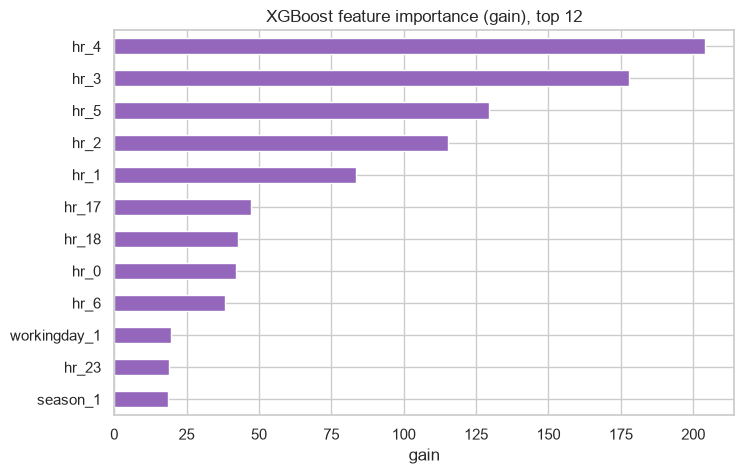

In [22]:
fixed_booster, _ = train_booster(dict(BEST_PARAMS, seed=SEED))

importance = pd.Series(fixed_booster.get_score(importance_type="gain")).sort_values(ascending=False)

ax = importance.head(12)[::-1].plot(kind="barh", figsize=(8, 5), color="tab:purple")
ax.set_title("XGBoost feature importance (gain), top 12")
ax.set_xlabel("gain")

## 13. Final model and a single evaluation on the test period

The chosen configuration is re-fitted on **train + validation** (more recent history, more data) with
the number of rounds found above, and evaluated once on the test period (2012-10-01 → 2012-12-31).

In [23]:
train_valid = pd.concat([train, valid])
X_full = make_features(train_valid, FEATURES)
y_full = train_valid["log_cnt"].to_numpy()

final_model = xgb.train(
    BEST_PARAMS,
    xgb.DMatrix(X_full, label=y_full),
    num_boost_round=BEST_ROUNDS,
)

pred_test_log = final_model.predict(xgb.DMatrix(X_test))
pred_test_cnt = np.clip(np.expm1(pred_test_log), 0, None)

# RMSLE should be computed on the same clipped count predictions we report/use,
# so we compare log1p(clipped counts) to log1p(actual counts).
test_metrics = {
    "RMSLE (log scale)": float(np.sqrt(mean_squared_error(np.log1p(test["cnt"]), np.log1p(pred_test_cnt)))),
    "RMSE (counts)": float(np.sqrt(mean_squared_error(test["cnt"], pred_test_cnt))),
    "MAE (counts)": float(mean_absolute_error(test["cnt"], pred_test_cnt)),
    "min predicted cnt": float(pred_test_cnt.min()),
    "mean actual cnt": float(test["cnt"].mean()),
}
pd.Series(test_metrics).round(3).to_frame("test period")

,test period
RMSLE (log scale),0.524
RMSE (counts),95.092
MAE (counts),56.675
min predicted cnt,2.523
mean actual cnt,219.196


Text(0.5, 1.0, 'Test period (Oct-Dec 2012): predicted vs. actual')

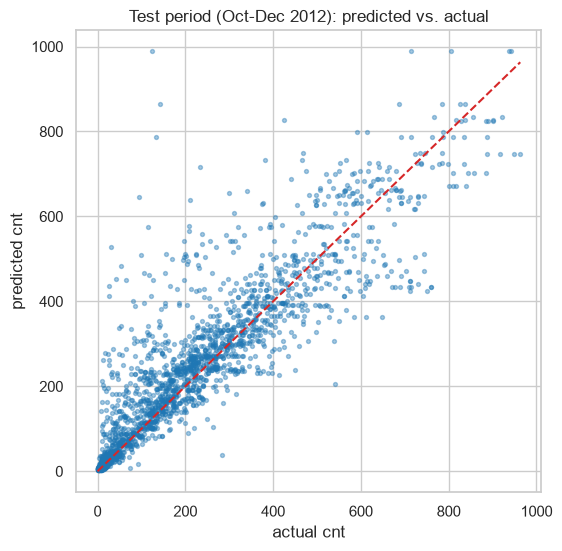

In [24]:
plt.figure(figsize=(6, 6))
plt.scatter(test["cnt"], pred_test_cnt, s=8, alpha=0.4, color="tab:blue")
plt.plot([0, test["cnt"].max()], [0, test["cnt"].max()], color="tab:red", linestyle="--")
plt.xlabel("actual cnt")
plt.ylabel("predicted cnt")
plt.title("Test period (Oct-Dec 2012): predicted vs. actual")

## 14. Saving the model

The model and the list of feature columns are stored together with `pickle` (module 5 of the course).
The column list is part of the artifact: at prediction time the one-hot matrix has to be rebuilt with
exactly the same 53 columns.

In [25]:
os.makedirs("models", exist_ok=True)
with open(MODEL_PATH, "wb") as f_out:
    pickle.dump({"features": FEATURES, "model": final_model}, f_out)

print("saved to", MODEL_PATH, "| size:", os.path.getsize(MODEL_PATH), "bytes")

saved to models/bike_demand_model.bin | size: 563807 bytes


In [26]:
# Reload the artifact and use it the way a web service would.
with open(MODEL_PATH, "rb") as f_in:
    saved = pickle.load(f_in)


def predict_rentals(hour_rows):
    """Predict rentals for a list of dicts with the calendar features."""
    rows = pd.DataFrame(hour_rows)[CATEGORICAL_FEATURES].astype(str)
    X = pd.get_dummies(rows, dtype=float).reindex(columns=saved["features"], fill_value=0.0)
    y_log = saved["model"].predict(xgb.DMatrix(X))
    return np.clip(np.expm1(y_log), 0, None).round().astype(int)


sample = test.iloc[[0, 500, 1000]][CATEGORICAL_FEATURES].to_dict(orient="records")
print("predicted:", predict_rentals(sample).tolist())
print("actual   :", test.iloc[[0, 500, 1000]]["cnt"].tolist())

# what the service would receive for one hour
print()
print(sample[0])

predicted: [44, 274, 33]
actual   : [45, 195, 18]

{'season': '4', 'yr': '1', 'mnth': '10', 'hr': '0', 'holiday': '0', 'weekday': '1', 'workingday': '1'}


## 15. Conclusions

**What was done.** Calendar-only regression on 17,379 hourly records with a chronological split
(train → 2012-06, validation → 2012-09, test → 2012-12), two baselines, a linear model, a decision tree,
a random forest and a tuned XGBoost, each stochastic model averaged over 5 seeds.

**Results on the validation period (RMSLE, mean ± std):**

* global mean baseline — 1.487
* weekday × hour average — 0.733
* linear regression — 0.590
* decision tree (depth 8) — 0.700 ± 0.000
* random forest (100 trees) — 0.394 ± 0.001
* tuned XGBoost (`eta=0.1`, `max_depth=4`, 329 rounds) — 0.320 ± 0.006

The ranking is the expected one: calendar structure gives most of the signal, trees learn the
hour × working-day interaction that the linear model cannot, and boosting beats a forest of independent
trees. The gain of XGBoost over the random forest (0.074 RMSLE) is much larger than the seed spread
(0.006 and 0.001), so it is supported by this experiment. The differences between the six tuning
configurations are *not*: the best and the second best are 0.3201 vs 0.3217 with spreads of about 0.005,
so the exact winner is noise and the search should not be read as "these are the right
hyperparameters".

**Test period.** The final model was refitted on train + validation and evaluated once: RMSLE 0.524,
MAE 56.7 rentals, RMSE 95.1 rentals per hour. Validation was 0.320, so the test error is about 60%
higher. This is drift, not a bug: July–September is peak season with a mean of 288 rentals per hour,
the test period averages 219, and the model has no weather input that could explain the autumn drop.
A single chronological holdout can also be lucky or unlucky — one number on one period is not a
generalisation estimate.

**Limitations**

* Only calendar features. The next step that would really help is **weather forecasts** for the next
  day (available from a weather API), not the observed weather in this dataset.
* 76 of the 731 days are incomplete (mostly one missing hour, a few heavily truncated), which adds a
  little noise to the measured error. There is nothing to impute — the hours were simply not recorded.
* `yr` is the only trend feature, so the two-year growth is captured as a single step, not as a curve.
* Early stopping and hyperparameter selection both use the validation period, which makes the
  validation score a little optimistic. The test period is untouched, which limits (but does not
  remove) the effect.
* One-hot month has no signal for months outside the training range in a strict extrapolation scenario;
  a cyclical (sin/cos) encoding of hour and month is the usual fix, but it did not matter here because
  all 12 months appear in training.

**Reproducing the run**

* environment: `pipenv install`, then `pipenv run jupyter lab notebook.ipynb`, run all cells top to bottom;
* seeds: `SEED = 42` initializes NumPy and the final XGBoost model; `SEEDS = [0, 1, 2, 3, 4]` are used for
  the repeated decision tree, random forest and XGBoost tuning runs so we can report mean +- std;
* run metadata (dataset SHA-256, Git SHA, library versions) and resolved hyperparameters are printed
  in sections 1–2 and 10.